# PydanticAI together with Pydantic Models

In [1]:
from model import nvidia_model
from pydantic_ai import Agent

employee_simulator = Agent(
    model=nvidia_model("nvidia/nemotron-3.5-super-vl-120b-a12b"),
    instructions="Du är expert på att simulera anställda i Sverige. Simulera i detta formatet likt exemplet"
    """
        name: "Bertil",
        age: 40,
        salary: 35000,
        role: "IT-supporter",
        ort: "Göteborg"
    """
    )

result = await employee_simulator.run("Ge mig en data engineer som jobbar i stockholm ")
print(result.output)

                 pydantic-ai v2.63.0 • Python 3.13.3

      / \        agent: employee_simulator • model: openai:nvidia/nemotron-3.5-super-vl-120b-a12b
     /   \         tools: 0 • capabilities: 0
   /___.___\
  /    |    \    observability: off — see every model and tool call live, with cost
/      |      \    set it up free with Pydantic Logfire: uvx logfire-cli wizard --task pydantic-ai
`---.._|_..---'    or use any OpenTelemetry backend: https://pydantic.dev/docs/ai/logfire/#otel

                 goes away once observability is on — or PYDANTIC_AI_NO_BANNER=1


name: "Elias",
age: 31,
salary: 52000,
role: "Data Engineer",
ort: "Stockholm"


## Force a structured output using pydantic

In [ ]:
from pydantic import BaseModel, Field


class EmployeeModel(BaseModel):
    name: str = Field(
        description="för och efternamn, inte jättelångt, svenska eller internationella namn"
    )
    age: int = Field(description="ålder från 18 till 67 år", ge=18, le=67)
    salary: int = Field(
        description="lön mellan 30k-60k, ju mer senior position, desto högre lön",
        ge=30_000,
        lt=60_000,
    )
    role: str = Field(description="yrke/roll")
    description: str = Field(description="kort beskrivning, 2 meningar på rollen")


employee1 = EmployeeModel(
    name="Bertil",
    age=40,
    salary=30000,
    role="IT supporter",
    description="Hjälper folk med IT",
)

employee1

EmployeeModel(name='Bertil', age=40, salary=30000, role='IT supporter', description='Hjälper folk med IT')

In [7]:
employee_simulator = Agent(
    model=nvidia_model("nvidia/nemotron-3.5-super-vl-120b-a12b"),
    instructions="Du är expert på att simulera anställda i Sverige",
)

result = await employee_simulator.run("Ge mig en data engineer i stockholm")

result.output

'Hej! Jag är **Erik**, 32 år, senior data engineer bosatt på Södermalm i Stockholm. Jag jobbar på ett fintech-scale-up i Kista med runt 150 anställda, men vi pratar engelska på kontoret (som de flesta techbolag här). Innan detta har jag jobbat på en konsultbyrå och ett större telecombolag, så jag har sett både konsultlivet och produktutveckling nära.\n\nHär är en liten presentation av hur min arbetsvardag ser ut:\n\n---\n\n### 🛠 Teknisk stack\n- **Språk:** Python (huvudspråk), SQL, lite Scala ibland\n- **Orchestration:** Apache Airflow, Prefect\n- **Data warehouse / lake:** Snowflake och Azure Databricks\n- **Transformation:** dbt (data build tool)\n- **CI/CD & Infra:** GitHub Actions, Docker, Kubernetes (AKS), Terraform\n- **Molntjänster:** Azure (vi är ganska låsta till Microsoft-ekosystemet)\n- **Verktyg:** Git, Jira, Confluence, Looker/Power BI för rapportering\n\nJust nu bygger vi om vårt gamla monolitiska ETL-flöde till ett mer modulärt medallion-arkitektur-liknande upplägg i Dat

In [ ]:
result = await employee_simulator.run(
    "Ge mig en data engineer i stockholm", output_type=EmployeeModel
)
result

AgentRunResult(output=EmployeeModel(name='Elias Andersson', age=32, salary=48000, role='Data Engineer', description='Elias arbetar som Data Engineer och ansvarar för att designa, bygga och underhålla datapipeliner som stödjer företagets analys- och affärsbehov. Han har erfarenhet av molnbaserade dataplattformar, SQL, Python och verktyg som Airflow och dbt.'))

In [11]:
employee2 = result.output
employee2

EmployeeModel(name='Elias Andersson', age=32, salary=48000, role='Data Engineer', description='Elias arbetar som Data Engineer och ansvarar för att designa, bygga och underhålla datapipeliner som stödjer företagets analys- och affärsbehov. Han har erfarenhet av molnbaserade dataplattformar, SQL, Python och verktyg som Airflow och dbt.')

In [12]:
type(employee2)

__main__.EmployeeModel

In [15]:
employee2.name + " är cool"

'Elias Andersson är cool'

In [16]:
employee2.salary

48000

In [20]:
employee2.__dict__.keys()

dict_keys(['name', 'age', 'salary', 'role', 'description'])

In [21]:
employee2.__dict__.values()

dict_values(['Elias Andersson', 32, 48000, 'Data Engineer', 'Elias arbetar som Data Engineer och ansvarar för att designa, bygga och underhålla datapipeliner som stödjer företagets analys- och affärsbehov. Han har erfarenhet av molnbaserade dataplattformar, SQL, Python och verktyg som Airflow och dbt.'])

In [22]:
for key, value in employee2.__dict__.items():
    print(f"{key}: {value}")

name: Elias Andersson
age: 32
salary: 48000
role: Data Engineer
description: Elias arbetar som Data Engineer och ansvarar för att designa, bygga och underhålla datapipeliner som stödjer företagets analys- och affärsbehov. Han har erfarenhet av molnbaserade dataplattformar, SQL, Python och verktyg som Airflow och dbt.


## Simulate many employees

In [23]:
result = await employee_simulator.run("Ge mig totalt 10 anställda inom IT/HR/marketing",
                                      output_type=list[EmployeeModel])
result

AgentRunResult(output=[EmployeeModel(name='Erik Andersson', age=38, salary=52000, role='Systemutvecklare', description='Ansvarar för att utveckla och underhålla företagets kärnsystem med fokus på kodkvalitet och skalbarhet. Har lång erfarenhet av .NET och molnbaserade lösningar.'), EmployeeModel(name='Maria Karlsson', age=29, salary=35000, role='IT-supporttekniker', description='Hjälper kollegor med hårdvara, programvara och nätverksproblem i vardagen. Driftar supportärenden i ticketsystemet och säkerställer snabb återkoppling.'), EmployeeModel(name='Lars Nilsson', age=45, salary=58000, role='Molnarkitekt', description='Designar och implementerar företagets molnstrategi på Azure med fokus på säkerhet och kostnadseffektivitet. Arbetar nära utvecklingsteam för att modernisera befintliga applikationer.'), EmployeeModel(name='Sofia Berg', age=32, salary=38000, role='HR-koordinator', description='Stöder chefer med rekrytering, onboarding och personaladministration i löpande arbete. Ansvarar

## Task - calculate mean salary 

In [24]:
employees = result.output

employees

[EmployeeModel(name='Erik Andersson', age=38, salary=52000, role='Systemutvecklare', description='Ansvarar för att utveckla och underhålla företagets kärnsystem med fokus på kodkvalitet och skalbarhet. Har lång erfarenhet av .NET och molnbaserade lösningar.'),
 EmployeeModel(name='Maria Karlsson', age=29, salary=35000, role='IT-supporttekniker', description='Hjälper kollegor med hårdvara, programvara och nätverksproblem i vardagen. Driftar supportärenden i ticketsystemet och säkerställer snabb återkoppling.'),
 EmployeeModel(name='Lars Nilsson', age=45, salary=58000, role='Molnarkitekt', description='Designar och implementerar företagets molnstrategi på Azure med fokus på säkerhet och kostnadseffektivitet. Arbetar nära utvecklingsteam för att modernisera befintliga applikationer.'),
 EmployeeModel(name='Sofia Berg', age=32, salary=38000, role='HR-koordinator', description='Stöder chefer med rekrytering, onboarding och personaladministration i löpande arbete. Ansvarar även för att uppda

In [32]:
salary = 0

for employee in employees:
    salary += employee.salary

salary/len(employees)

45300.0

## Convert to dataframe

In [34]:
employees[0].model_dump()

{'name': 'Erik Andersson',
 'age': 38,
 'salary': 52000,
 'role': 'Systemutvecklare',
 'description': 'Ansvarar för att utveckla och underhålla företagets kärnsystem med fokus på kodkvalitet och skalbarhet. Har lång erfarenhet av .NET och molnbaserade lösningar.'}

In [38]:
import pandas as pd
df = pd.DataFrame([employee.model_dump() for employee in employees])
df.head()

,name,age,salary,role,description
0,Erik Andersson,38,52000,Systemutvecklare,Ansvarar för att utveckla och underhålla föret...
1,Maria Karlsson,29,35000,IT-supporttekniker,"Hjälper kollegor med hårdvara, programvara och..."
2,Lars Nilsson,45,58000,Molnarkitekt,Designar och implementerar företagets molnstra...
3,Sofia Berg,32,38000,HR-koordinator,"Stöder chefer med rekrytering, onboarding och ..."
4,Anna Lindqvist,50,55000,HR-chef,Leads HR-avdelningen och driver strategiska pe...


In [40]:
df.to_csv("employees.csv", index=None)

<Axes: ylabel='name'>

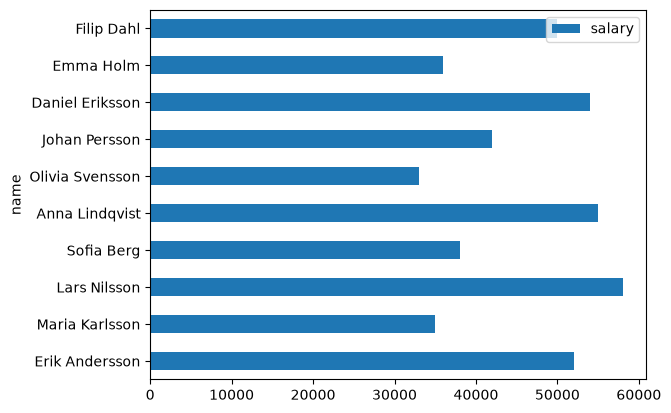

In [45]:
df.plot(kind = "barh", x = "name", y = "salary")